# Chapter 5 — Social Network Analytics: Influence, Communities and Homophily

## Why this chapter matters

These methods turn social-media traces into careful, measurable evidence without treating posts as the whole population.

## Learning outcomes

- Build and inspect an attributed graph.
- Compare centrality, communities and homophily.

## Concepts in simple language

Nodes represent users and edges interactions. Graphs may be directed/undirected and weighted/unweighted. Degree, density, paths, components and clustering describe structure. Degree, betweenness, closeness and PageRank operationalize different influence ideas. Communities are dense groups; bridge users connect them. Homophily is similarity, not causal influence.

## Dataset introduction

The users and edges form several imperfectly homophilous communities with weakly connected users. All data are synthetic teaching data; they contain no real private users.

In [1]:
from pathlib import Path
import random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
current_path = Path.cwd()
if (current_path / 'data').exists(): repository_root = current_path
elif (current_path.parent / 'data').exists(): repository_root = current_path.parent
else: raise FileNotFoundError('Could not find the repository data directory.')
data_directory = repository_root / 'data'
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Data directory:', data_directory)


Python: 3.9.6 | pandas: 2.2.3
Data directory: /Users/mehrdadjalali/Documents/SRH-Courses/Modules/Social Media Analytics and Sentiment Analysis/Github/SocialMediaAnayltics/data


## Instructor-guided walkthrough

We build the attributed graph, inspect it, calculate network statistics, visualize structure, rank centrality, detect communities, and measure assortativity.

## Step-by-step Python implementation

### Function guide: `nx.from_pandas_edgelist / nx.Graph`

**Library:** NetworkX  
**Purpose:** Create a graph and add edge attributes.  
**Input/return:** Takes the objects shown below and returns the stated result.  
**Common mistake:** Interpreting a score as causal proof.  
**Simple example:** See the next small code cell.

| Parameter | Value used | Meaning | What happens if changed? |
|---|---:|---|---|
| source/target | columns | Edge endpoints | Swapping matters in directed graphs |
| edge_attr | weight, interaction_type | Edge metadata | False drops attributes |
| create_using | nx.Graph() | Undirected graph | nx.DiGraph() preserves direction |

In [2]:
import networkx as nx
users=pd.read_csv(data_directory/'social_network_users.csv'); edges=pd.read_csv(data_directory/'social_network_edges.csv')
G=nx.from_pandas_edgelist(edges,source='source',target='target',edge_attr=['weight','interaction_type','timestamp'],create_using=nx.Graph())
for record in users.to_dict('records'):
    uid=record.pop('user_id'); G.add_node(uid,**record)
print(G); print('Sample nodes:',list(G.nodes(data=True))[:2]); print('Sample edges:',list(G.edges(data=True))[:2])

Graph with 50 nodes and 100 edges
Sample nodes: [('u01', {'community_label': 'community_1', 'region': 'north', 'interest': 'mobility', 'account_type': 'individual', 'sentiment_tendency': 'neutral'}), ('u02', {'community_label': 'community_1', 'region': 'north', 'interest': 'mobility', 'account_type': 'individual', 'sentiment_tendency': 'negative'})]
Sample edges: [('u01', 'u02', {'weight': 3, 'interaction_type': 'mention', 'timestamp': '2025-02-01T02:00:00'}), ('u01', 'u03', {'weight': 4, 'interaction_type': 'reply', 'timestamp': '2025-02-01T03:00:00'})]


### Function guide: `network statistics`

**Library:** NetworkX  
**Purpose:** Describe graph cohesion and reachability.  
**Input/return:** Takes the objects shown below and returns the stated result.  
**Common mistake:** Interpreting a score as causal proof.  
**Simple example:** See the next small code cell.

| Parameter | Value used | Meaning | What happens if changed? |
|---|---:|---|---|
| weight | None | Treat each edge equally | 'weight' uses interaction strength |
| connected_components | G | Sets of reachable nodes | Directed graphs need weak/strong variants |
| average_clustering | G | Mean closed-neighbor fraction | Weight changes interpretation |

In [3]:
stats={'nodes':G.number_of_nodes(),'edges':G.number_of_edges(),'density':nx.density(G),'average_clustering':nx.average_clustering(G),'components':nx.number_connected_components(G)}
print(stats); print('Component sizes:',sorted(map(len,nx.connected_components(G)),reverse=True))

{'nodes': 50, 'edges': 100, 'density': 0.08163265306122448, 'average_clustering': 0.4151428571428572, 'components': 3}
Component sizes: [48, 1, 1]


### Function guide: `nx.spring_layout`

**Library:** NetworkX  
**Purpose:** Calculate display positions; it does not alter edges.  
**Input/return:** Takes the objects shown below and returns the stated result.  
**Common mistake:** Interpreting a score as causal proof.  
**Simple example:** See the next small code cell.

| Parameter | Value used | Meaning | What happens if changed? |
|---|---:|---|---|
| seed | 42 | Reproducible positions | Another seed moves nodes visually |
| k | 0.5 | Preferred spacing | Larger spreads nodes |
| iterations | 50 | Layout refinement | More may stabilize positions |

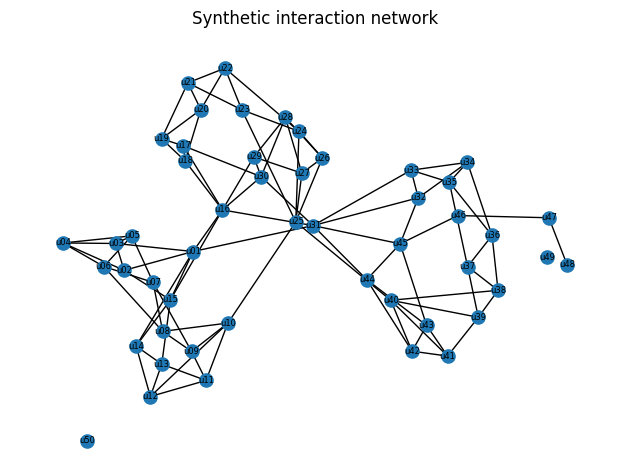

In [4]:
pos=nx.spring_layout(G,seed=RANDOM_SEED,k=.5,iterations=50); nx.draw_networkx(G,pos,node_size=90,font_size=6,with_labels=True); plt.title('Synthetic interaction network'); plt.axis('off'); plt.tight_layout(); plt.show()

### Function guide: `centrality and PageRank`

**Library:** NetworkX  
**Purpose:** Rank structurally prominent nodes.  
**Input/return:** Takes the objects shown below and returns the stated result.  
**Common mistake:** Interpreting a score as causal proof.  
**Simple example:** See the next small code cell.

| Parameter | Value used | Meaning | What happens if changed? |
|---|---:|---|---|
| alpha | 0.85 | PageRank continuation probability | Lower values flatten scores |
| weight | weight | Interaction-strength attribute | None treats edges equally |
| max_iter | 100 | Iteration cap | Too low may not converge |
| tol | 1e-06 | Convergence tolerance | Smaller is more precise/slower |

In [5]:
central=pd.DataFrame({'degree':nx.degree_centrality(G),'betweenness':nx.betweenness_centrality(G,weight=None),'closeness':nx.closeness_centrality(G),'pagerank':nx.pagerank(G,alpha=.85,weight='weight',max_iter=100,tol=1e-6)})
display(central.sort_values('betweenness',ascending=False).head(8)); print('Bridge candidates have high betweenness.')

,degree,betweenness,closeness,pagerank
u31,0.142857,0.282526,0.344135,0.031329
u25,0.122449,0.237962,0.313067,0.030691
u01,0.122449,0.182466,0.326678,0.025845
u16,0.142857,0.169376,0.336430,0.036181
u40,0.102041,0.157059,0.294651,0.019274
u10,0.102041,0.146948,0.283532,0.026057
u45,0.102041,0.131770,0.288985,0.028117
u46,0.040816,0.076531,0.227685,0.016807


Bridge candidates have high betweenness.


### Function guide: `greedy_modularity_communities`

**Library:** NetworkX  
**Purpose:** Return a list of node sets that greedily improve modularity.  
**Input/return:** Takes the objects shown below and returns the stated result.  
**Common mistake:** Interpreting a score as causal proof.  
**Simple example:** See the next small code cell.

| Parameter | Value used | Meaning | What happens if changed? |
|---|---:|---|---|
| G | graph | Network structure | Different graph changes groups |
| weight | weight | Edge strength | None ignores weights |
| resolution | 1 | Community scale | Higher often finds smaller groups |

In [6]:
communities=list(nx.community.greedy_modularity_communities(G,weight='weight',resolution=1)); modularity=nx.community.modularity(G,communities,weight='weight'); print('Communities:',[len(x) for x in communities],'modularity:',round(modularity,3))
for attribute in ['community_label','region','interest']:
    print(attribute,'assortativity:',round(nx.attribute_assortativity_coefficient(G,attribute),3))

Communities: [9, 8, 8, 8, 8, 7, 1, 1] modularity: 0.647
community_label assortativity: 0.883
region assortativity: 0.883
interest assortativity: 0.88


## Output interpretation

Read values in context: inspect examples, sample sizes, uncertainty, and possible bias. Association is not causation.

## Common mistakes

Common errors include ignoring missing data, leakage, class imbalance, direction of edges, and treating model confidence as research certainty.

## Challenge 1: Top influential users using three measures

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Challenge 2: Detect communities and compare labels

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Challenge 3: Measure homophily for two attributes

**Objective:** Apply a method demonstrated above.

**Tasks:** Adapt the starter code, check the result, and write two evidence-based sentences.

**Starter code:** `# result = ...`

**Hint:** Reuse the named columns and functions from the walkthrough.

**Expected output:** A small table or metric with no missing explanation.

**Interpretation question:** What does the result support, and what can it not prove?

**Self-check:** Did you report the sample size, units, and one limitation?

## Chapter summary

The walkthrough connected a research question to transparent data preparation, analysis, visual evidence, and cautious interpretation.

## Connection to the group project

Select network definitions that match the research question and avoid causal language.